# Chromatic lookup surface geometry


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：chromatic_lookup_surface_geometry

**观测 y：** pattern(1, 3, 650, 650, 3)；white(1, 3, 650, 650, 3)；left_color(1, 3, 650, 650, 25)；right_color(1, 3, 25, 749)；left_depth(1, 650, 650, 25)；right_depth(1, 25, 749)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 相机轴向表面深度(mm)。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 独立平面标定颜色/深度字典将深度映射到RGB比值。本地路径为 `solvers.solve→decode_rays穷举最近颜色样本`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 3, 5, 9, 11, 13, 15, 17, 19（cell编号按文件内从0计）。章节包括：# Chromatic lookup surface geometry；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；### Actual source helper comparisons；### Calibration-rank sensitivity；### Generated ratio perturbations；### Four additional real contexts and an uncorrected calibration failure。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 无几何真值；标定sample510异常不能删值假装真值。

<!-- inverse-evidence-audit:20261026:end -->

## 1. Problem
Recover absolute camera-axial surface depth from measured projected-color and alternating white exposures. This is an observation-to-geometry inverse problem: the illumination, camera response and planar-board calibration are known, while object depth is unknown. The benchmark binds the **first three consecutive frames**, chosen before any inverse run. It does not claim independent geometric truth.

The paper's empirical nearest-color decoder is the primary method. Spatial coarse-to-fine and temporal-window APIs are additional computed comparisons. Their repository helper behavior differs from the paper's adaptive widening: we preserve the actual fixed-window implementation and identify its interface qualifications. Data: real author-distributed silicone-bunny drop, complete650x650 calibrated region,749 calibration samples.

The story distinguishes **paper reports**, **our original-code numeric runs** and **fresh local computations below**. No paper-reported speed or geometric error is presented as a measurement of this implementation.

In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,tempfile,platform,subprocess
for key in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS']: os.environ[key]='1'
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if not (ROOT/'src').is_dir(): raise RuntimeError('Run from this task or its notebooks directory')
sys.path.insert(0,str(ROOT))
import numpy as np,scipy,matplotlib
import matplotlib.pyplot as plt
from src.preprocessing import load_observations,normalize_observations
from src.physics_model import calibration_rays,project_depth_to_points
from src.solvers import solve,coarse_to_fine,temporal_continuation
from src.generate_data import perturb_normalized
from src.visualization import depth_image,export_figure
EXPORT=Path(os.environ.get('IMAGING_REVIEW_EXPORT',str(Path(tempfile.gettempdir())/'imaging101_lookup_review')))
EXPORT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'figure.dpi':105})
figures=[]; measurements={}; notebook_start=time.perf_counter()
def save(fig,name,arrays,description):
    figures.append(export_figure(fig,EXPORT,name,arrays,description)); plt.show(); plt.close(fig)
print({'python':sys.version,'platform':platform.platform(),'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'threads':{k:os.environ[k] for k in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS']}})


{'python': '3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]', 'platform': 'Windows-10-10.0.26200-SP0', 'numpy': '2.4.6', 'scipy': '1.17.1', 'matplotlib': '3.11.1', 'threads': {'OPENBLAS_NUM_THREADS': '1', 'OMP_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1'}}


## 2. Data
The native1920x1080 camera stores12-bit ADU in uint16. The independent low-rank calibration fixes ROI(left,top,right,bottom)=(650,200,1300,850); no resizing or target-dependent calibration is applied. The camera alternates pattern/white at900 exposures/s, giving450 pairs/s; exposures last1ms. RGB channel order is explicit.

For every frame, define the white minimum over color channels, and retain pixels whose minimum exceeds5% of its image maximum. This is an input-only support; no residual, depth or target-based rejection is allowed. Ratios outside that support are zero internally and submitted depth is exactly−1mm. The displays below show all pixels, and ratio display clipping is explicitly visual only.

{'pattern': ((1, 3, 650, 650, 3), 'uint16'), 'white': ((1, 3, 650, 650, 3), 'uint16'), 'left_color': ((1, 3, 650, 650, 25), 'float32'), 'right_color': ((1, 3, 25, 749), 'float32'), 'left_depth': ((1, 650, 650, 25), 'float32'), 'right_depth': ((1, 25, 749), 'float32')}
raw SHA256 cb669bca9942ac14fe807d866ae47c0922252cbb8816c4bea77ff4cd1e004ba3


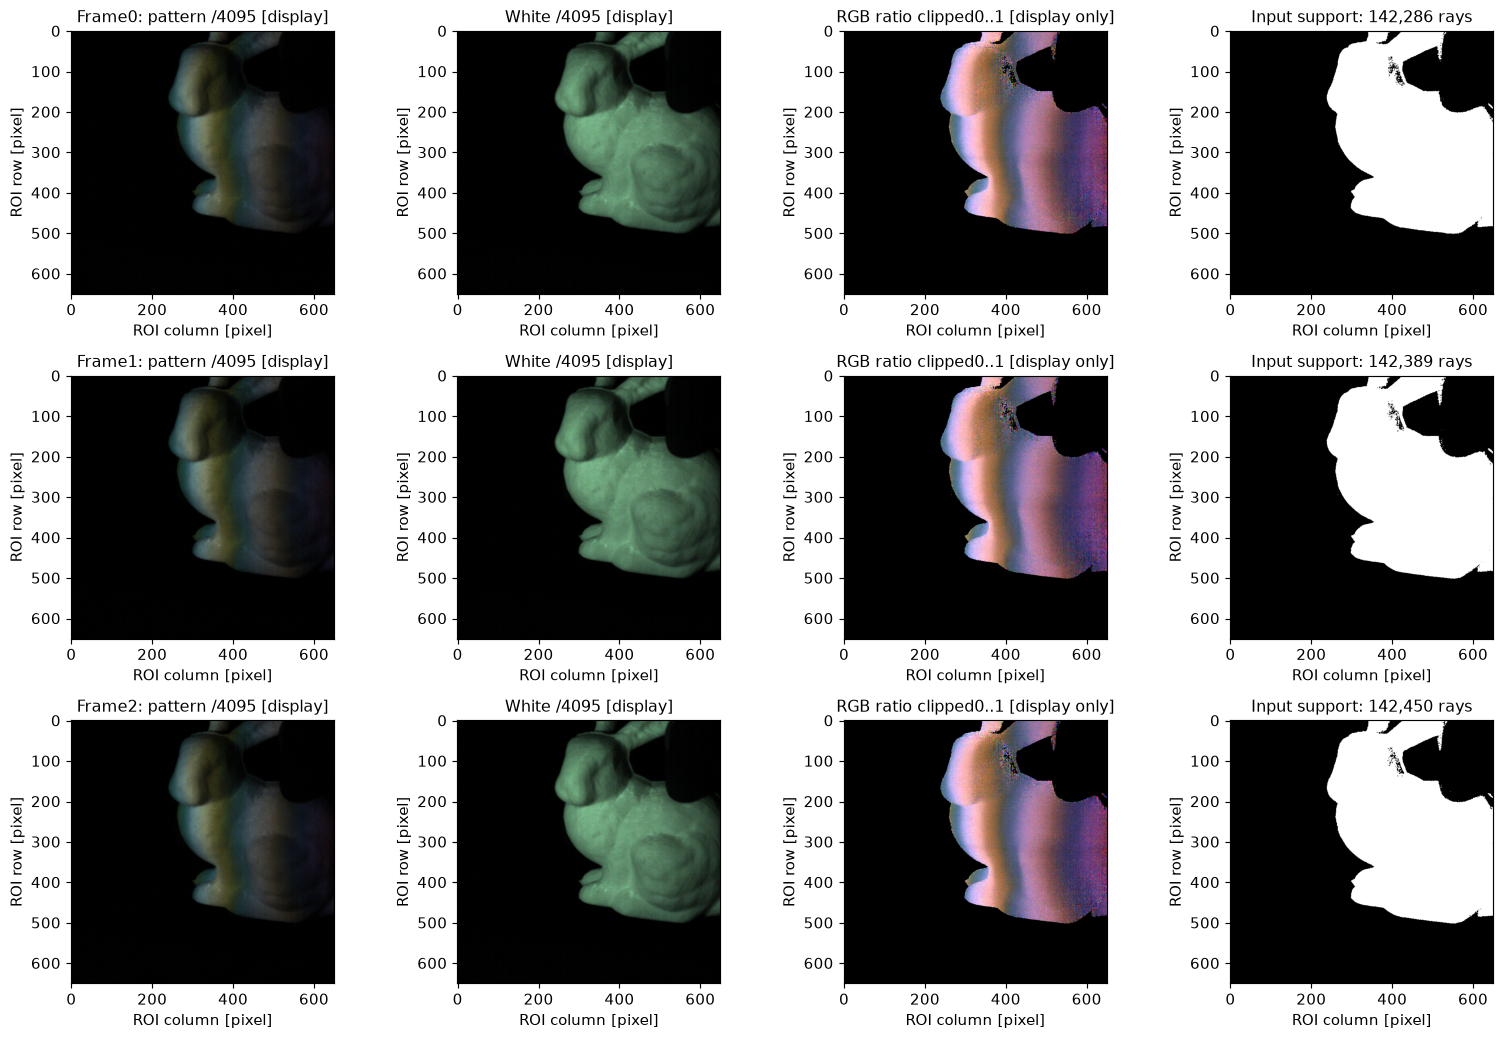

In [2]:
raw=load_observations(ROOT/'data/raw_data.npz')
q,mask=normalize_observations(raw['pattern'][0],raw['white'][0])
print({k:(v.shape,str(v.dtype)) for k,v in raw.items()})
print('raw SHA256',hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())
fig,ax=plt.subplots(3,4,figsize=(15,10))
for f in range(3):
    ax[f,0].imshow(raw['pattern'][0,f]/4095); ax[f,0].set_title(f'Frame{f}: pattern /4095 [display]')
    ax[f,1].imshow(raw['white'][0,f]/4095); ax[f,1].set_title('White /4095 [display]')
    ax[f,2].imshow(np.clip(q[f],0,1)); ax[f,2].set_title('RGB ratio clipped0..1 [display only]')
    ax[f,3].imshow(mask[f],cmap='gray',vmin=0,vmax=1); ax[f,3].set_title(f'Input support: {mask[f].sum():,} rays')
    for a in ax[f]: a.set(xlabel='ROI column [pixel]',ylabel='ROI row [pixel]')
save(fig,'fig01_measured_acquisition',dict(pattern=raw['pattern'],white=raw['white'],ratio=q,support=mask),'Allthree real measured pattern/white exposures; display scaling does not alter reconstruction.')


## 3. Physics
For frame $f$, pixel $p$, color $c$, sample $k$ and factor $r$, the dimensionless ratio $q$ follows an empirical calibrated color $C$ plus model discrepancy $\eta$. Axial depth is $D$ in mm:

$$
q_{f,p,c}=I^P_{f,p,c}/I^W_{f,p,c}=C_{p,k,c}+\eta_{f,p,c},\qquad
C_{p,k,c}=\sum_r L^C_{c,p,r}R^C_{c,r,k},\qquad
D_{p,k}=\sum_r L^D_{p,r}R^D_{r,k}.
$$

The factors come from a moving planar calibration board, independently of object geometry. White normalization approximately removes stationary diffuse reflectance; exposure-to-exposure motion, shadows, glossy reflection and color ambiguity break that idealization. The raw planned750 translations yield749 supplied samples; their camera-axial depths vary with ray. Sample order must not be replaced by a uniform depth grid.

The following rays are chosen by fixed sensor coordinates, before looking at reconstruction quality. Repeated colors explain why a low photometric residual does not prove geometrical accuracy.

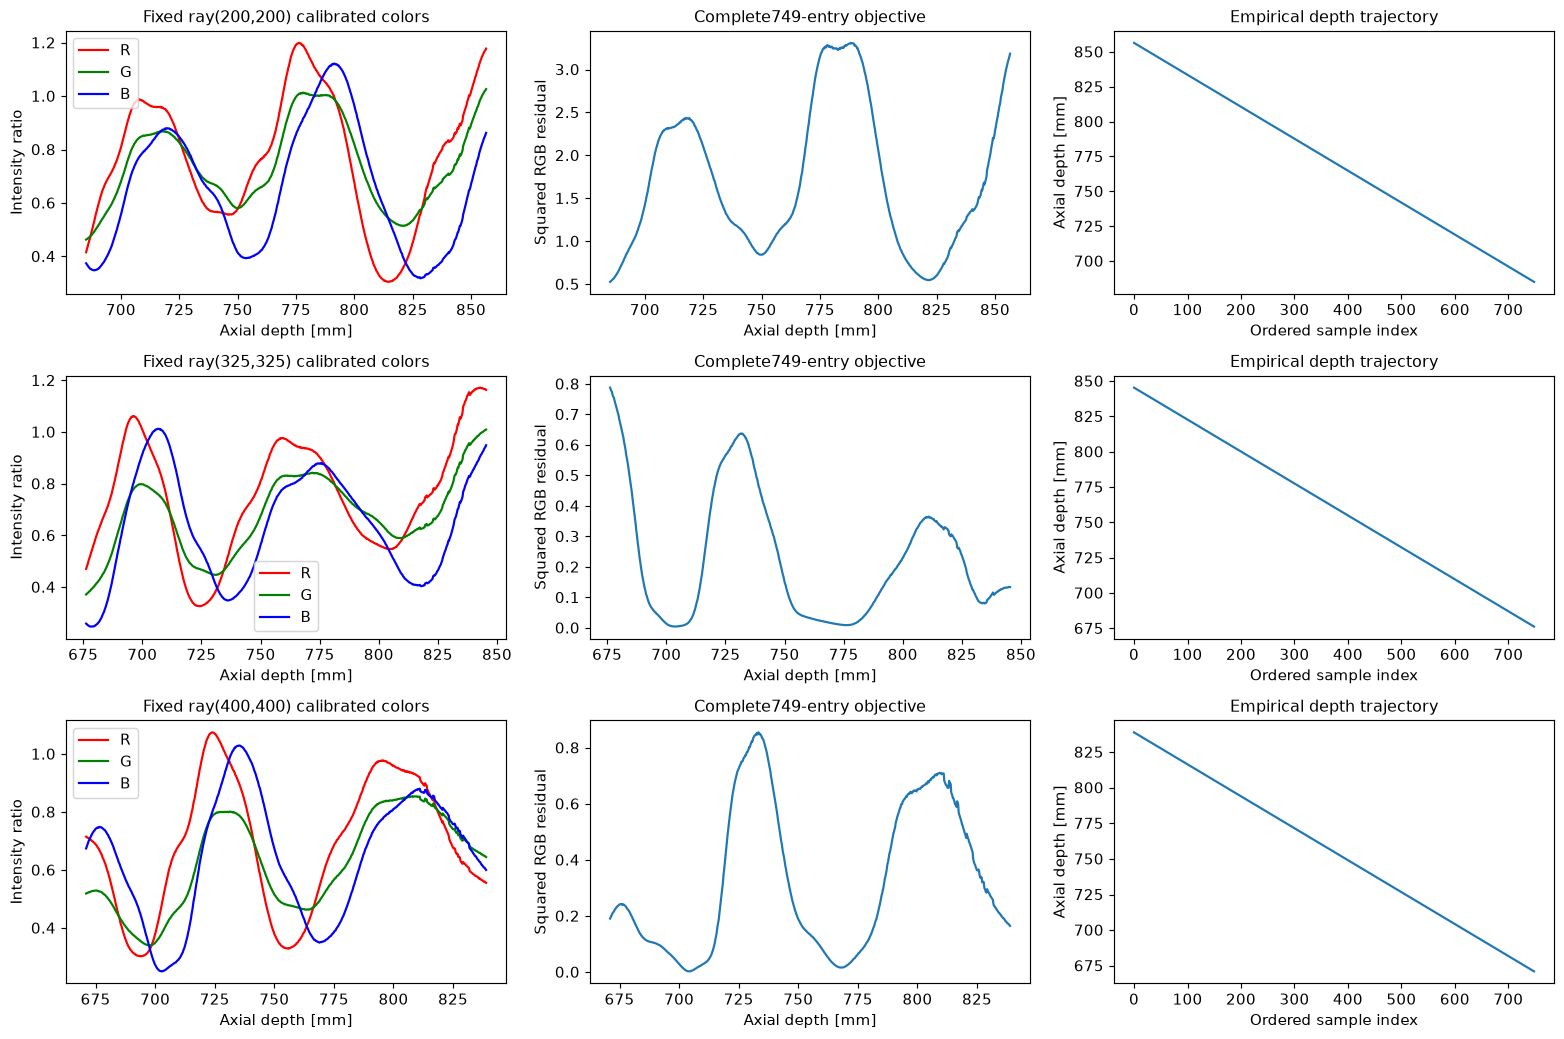

In [3]:
fixed_rows=np.array([200*650+200,325*650+325,400*650+400],dtype=np.int64)
cc,dd=calibration_rays(raw,fixed_rows)
fig,ax=plt.subplots(3,3,figsize=(15,10)); objectives=[]
for j,row in enumerate(fixed_rows):
    y,x=divmod(int(row),650)
    for c,color in enumerate(['r','g','b']): ax[j,0].plot(dd[j],cc[j,:,c],color=color,label='RGB'[c])
    ax[j,0].set(title=f'Fixed ray({y},{x}) calibrated colors',xlabel='Axial depth [mm]',ylabel='Intensity ratio'); ax[j,0].legend()
    objective=np.sum((cc[j]-q[0,y,x])**2,axis=1);objectives.append(objective)
    ax[j,1].plot(dd[j],objective);ax[j,1].set(xlabel='Axial depth [mm]',ylabel='Squared RGB residual',title='Complete749-entry objective')
    ax[j,2].plot(np.arange(749),dd[j]);ax[j,2].set(xlabel='Ordered sample index',ylabel='Axial depth [mm]',title='Empirical depth trajectory')
save(fig,'fig02_calibrated_forward_model',dict(rows=fixed_rows,colors=cc,depths=dd,objective=np.asarray(objectives)),'Fixed-coordinate empirical calibration and actual measured objective, no outcome-selected ray.')


## 4. Method
The primary inverse explicitly evaluates every calibration candidate at each supported camera ray:

$$
\widehat k_{f,p}=\arg\min_k\sum_c(C_{p,k,c}-q_{f,p,c})^2,\qquad
\widehat z_{f,p}=D_{p,\widehat k_{f,p}}.
$$

An exact tie chooses the earliest sample. Matrix products expand bounded blocks of2048 rays, shared over three frames; no full dense table or domain library is imported. Source float32 channel accumulation and normalization conventions are preserved. There is no iterative convergence criterion for this finite exhaustive inverse.

The original CPU function attempted scalar `math.sqrt` on an image and failed. The private original oracle uses only an independently checked array-sqrt API correction. General disk allocation preserves full matrix multiplication/stack bytes. Additional source controls also need a proven broadcast correction in their depth gather. These are qualified source runs, not an unchanged-reproduction claim.

Fresh code below reconstructs **all bound observations**, writes the standard submission, then invokes the independent evaluator. Archived source arrays are loaded only after reconstruction for comparison.

In [4]:
fresh=solve(raw)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=fresh['reconstruction'][None])
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
checked=subprocess.run(command,cwd=ROOT,capture_output=True,text=True)
assert checked.returncode==0,(checked.stdout,checked.stderr)
judge=json.loads((ROOT/'output/judge_report.json').read_text())
with np.load(ROOT/'notebooks/reference_outputs/upstream_primary.npz',allow_pickle=False) as z: upstream={k:z[k] for k in z.files}
measurements['primary']={'seconds':fresh['seconds'],'judge':judge,'original_max_absolute_mm':float(np.max(abs(fresh['reconstruction']-upstream['reconstruction'][0])))}
print(json.dumps(measurements['primary'],indent=2))


{
  "seconds": 8.470719299992197,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "frame0_ncc": 1.0,
      "frame0_nrmse": 9.55443271804178e-09,
      "frame0_maximum_absolute_error_mm": 0.0001220703125,
      "frame0_observation_rms": 0.07039935568680147,
      "frame1_ncc": 1.0,
      "frame1_nrmse": 8.748888393178176e-09,
      "frame1_maximum_absolute_error_mm": 0.0001220703125,
      "frame1_observation_rms": 0.07032304854200729,
      "frame2_ncc": 1.0,
      "frame2_nrmse": 8.393515101770479e-09,
      "frame2_maximum_absolute_error_mm": 0.0001220703125,
      "frame2_observation_rms": 0.07043824044554232
    },
    "thresholds": {
      "frame0_ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "frame0_nrmse": {
        "comparison": "<=",
        "boundary": 1e-06
      },
      "frame0_maximum_absolute_error_mm": {
        "comparison": "<=",
        "boundary": 0.001
      },
      "frame0_observation_rms": {
       

## 5. Results
### Primary full-field geometry and original parity
The independent source result is a **method reference**, not measured true geometry. Each complete support is evaluated separately without shift, rescaling or depth clipping. Full XYZ visualizations use the independently calibrated camera intrinsics and Brown–Conrady distortion; their units are mm, with axes right/down/forward. Scatter displays retain every supported ray, rather than outcome-selecting a smoother surface.

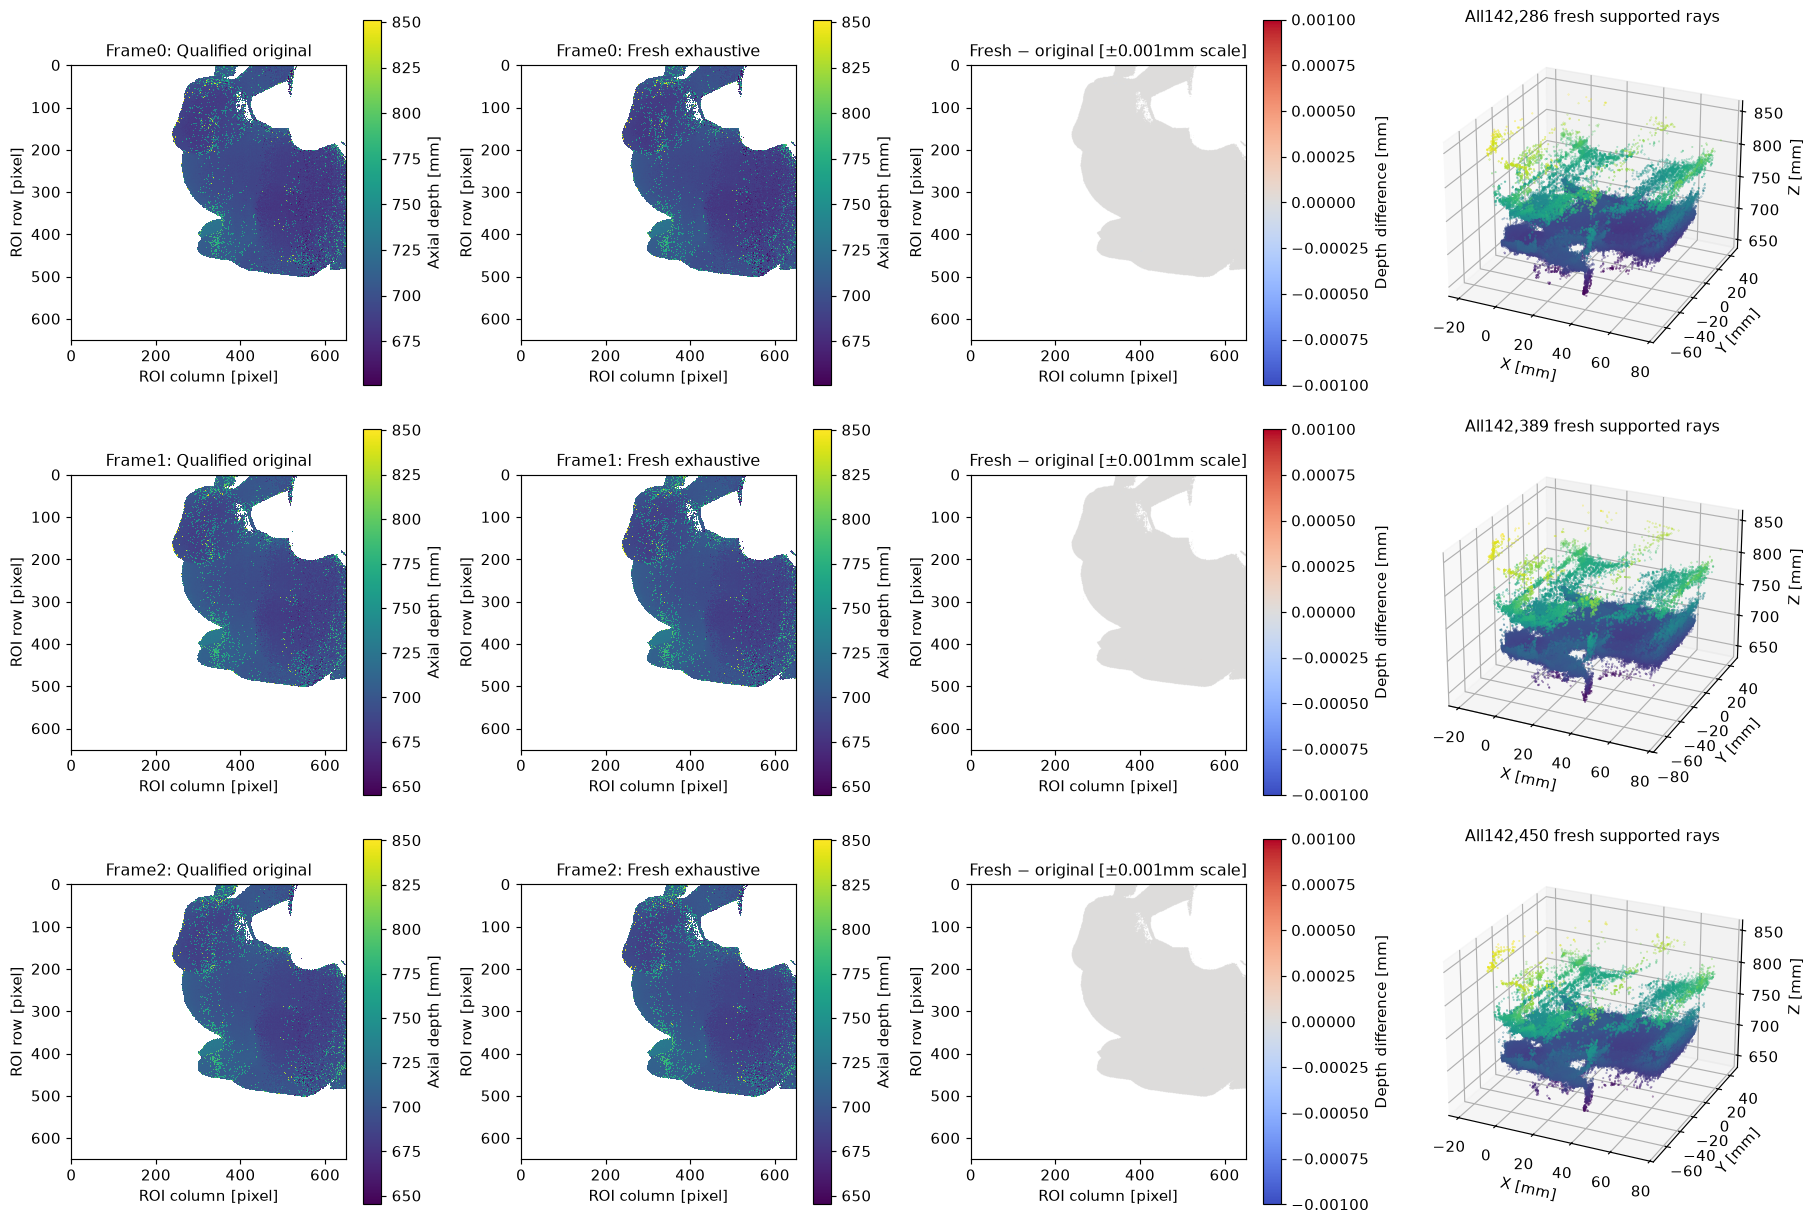

In [5]:
K=np.array([[3580.915139167154,0,967.7411991347725],[0,3578.1633141223797,509.395929381727],[0,0,1.]])
dist=np.array([-.05202839890657609,-.05977211653771139,.0014034145040185428,-.00031193552659360146,.3585615042719389])
fig=plt.figure(figsize=(17,12));points=[]
for f in range(3):
    z=fresh['reconstruction'][f];ref=upstream['reconstruction'][0,f];m=mask[f]
    lo=float(min(z[m].min(),ref[m].min()));hi=float(max(z[m].max(),ref[m].max()))
    for col,data,title in [(0,ref,'Qualified original'),(1,z,'Fresh exhaustive')]:
        a=fig.add_subplot(3,4,f*4+col+1);im=depth_image(a,data,m,f'Frame{f}: {title}',lo,hi);fig.colorbar(im,ax=a,label='Axial depth [mm]')
    a=fig.add_subplot(3,4,f*4+3);diff=z-ref
    im=a.imshow(np.ma.array(diff,mask=~m),cmap='coolwarm',vmin=-.001,vmax=.001);a.set(title='Fresh − original [±0.001mm scale]',xlabel='ROI column [pixel]',ylabel='ROI row [pixel]');fig.colorbar(im,ax=a,label='Depth difference [mm]')
    xyz=project_depth_to_points(z,K,dist);points.append(xyz)
    a=fig.add_subplot(3,4,f*4+4,projection='3d');p=xyz[m];a.scatter(p[:,0],p[:,1],p[:,2],c=p[:,2],cmap='viridis',s=.10,rasterized=True)
    a.set(title=f'All{len(p):,} fresh supported rays',xlabel='X [mm]',ylabel='Y [mm]',zlabel='Z [mm]');a.view_init(elev=25,azim=-65)
save(fig,'fig03_primary_geometry_and_parity',dict(fresh=fresh['reconstruction'],original=upstream['reconstruction'],support=mask,xyz=np.asarray(points)),'All bound surfaces, source parity and full supported camera-space point clouds; no independent geometry truth.')


### Actual source helper comparisons
Compute coarse-to-fine at strides8,4,2,1 and fixed half-windows374,125,50,25, epsilon0.1. Its last index is **relative** to a window; it is not a global index. The first window has748 candidates and excludes the last source sample. The integer Gaussian prior and nearest fill conventions are retained.

Compute temporal continuation directly with the previous **global exhaustive** index and half-window25 for the two consecutive transitions. This is the actual `tc_lut` API comparison; it does not claim the broken repository CLI's adaptive fallback. Every field, including disagreements, remains visible.

[
  {
    "frame": 0,
    "c2f_source_max_mm": 0.0001220703125,
    "c2f_exhaustive_rms_mm": 20.961265563964844,
    "c2f_rgb_rms": 0.11882008948387969
  },
  {
    "frame": 1,
    "c2f_source_max_mm": 0.0001220703125,
    "c2f_exhaustive_rms_mm": 20.992835998535156,
    "c2f_rgb_rms": 0.11898876610271052,
    "tc_source_max_mm": 0.0001220703125,
    "tc_exhaustive_rms_mm": 27.01063346862793
  },
  {
    "frame": 2,
    "c2f_source_max_mm": 6.103515625e-05,
    "c2f_exhaustive_rms_mm": 20.695598602294922,
    "c2f_rgb_rms": 0.12261206743030006,
    "tc_source_max_mm": 166.55303955078125,
    "tc_exhaustive_rms_mm": 26.764734268188477
  }
]


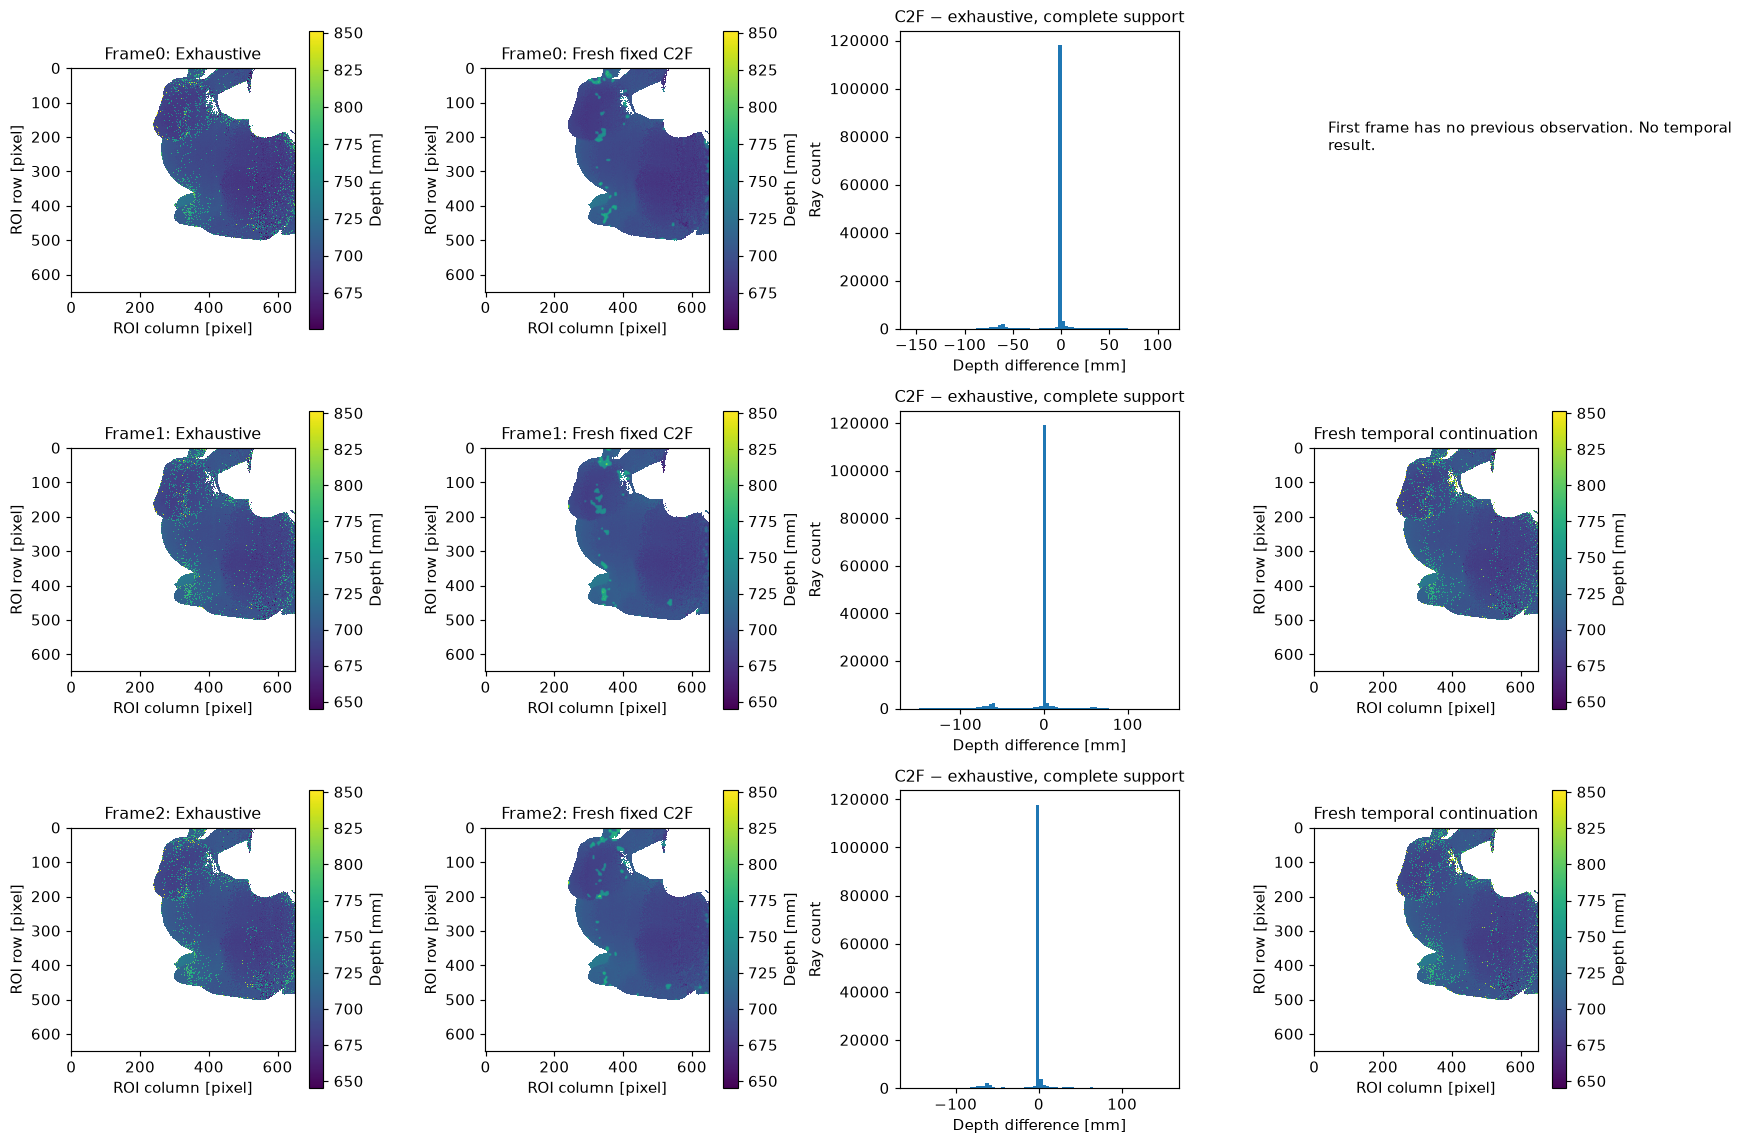

In [6]:
with np.load(ROOT/'notebooks/reference_outputs/upstream_controls.npz',allow_pickle=False) as z: original_controls={k:z[k] for k in z.files}
c2f=[coarse_to_fine(raw,q[f],mask[f]) for f in range(3)]
tc={f:temporal_continuation(raw,q[f],mask[f],fresh['index'][f-1]) for f in [1,2]}
control_rows=[];fig,ax=plt.subplots(3,4,figsize=(17,11))
for f in range(3):
    z=fresh['reconstruction'][f];m=mask[f]
    common=[z[m],c2f[f]['reconstruction'][m]]+([tc[f]['reconstruction'][m]] if f else [])
    lo=min(float(x.min()) for x in common);hi=max(float(x.max()) for x in common)
    for col,result,title in [(0,z,'Exhaustive'),(1,c2f[f]['reconstruction'],'Fresh fixed C2F')]:
        im=depth_image(ax[f,col],result,m,f'Frame{f}: {title}',lo,hi);fig.colorbar(im,ax=ax[f,col],label='Depth [mm]')
    delta=c2f[f]['reconstruction']-z
    ax[f,2].hist(delta[m],bins=80);ax[f,2].set(title='C2F − exhaustive, complete support',xlabel='Depth difference [mm]',ylabel='Ray count')
    source=original_controls[f'c2f_depth_{f}'];error=float(np.max(abs(c2f[f]['reconstruction']-source)))
    row={'frame':f,'c2f_source_max_mm':error,'c2f_exhaustive_rms_mm':float(np.sqrt(np.mean(delta[m]**2))),'c2f_rgb_rms':float(np.sqrt(np.mean(c2f[f]['loss'][m].astype(float)**2)))}
    if f:
        im=depth_image(ax[f,3],tc[f]['reconstruction'],m,'Fresh temporal continuation',lo,hi);fig.colorbar(im,ax=ax[f,3],label='Depth [mm]')
        row['tc_source_max_mm']=float(np.max(abs(tc[f]['reconstruction']-original_controls[f'tc_depth_{f}'])))
        row['tc_exhaustive_rms_mm']=float(np.sqrt(np.mean((tc[f]['reconstruction'][m]-z[m])**2)))
    else: ax[f,3].axis('off');ax[f,3].text(.05,.6,'First frame has no previous observation. No temporal result.',wrap=True,transform=ax[f,3].transAxes)
    control_rows.append(row)
measurements['actual_helper_comparisons']=control_rows;print(json.dumps(control_rows,indent=2))
save(fig,'fig04_actual_spatiotemporal_helpers',dict(exhaustive=fresh['reconstruction'],coarse=np.stack([x['reconstruction'] for x in c2f]),temporal=np.stack([tc[f]['reconstruction'] for f in [1,2]]),support=mask),'Fresh full source-API comparisons; missing first temporal frame is explicitly absent, not filled with zero.')


### Calibration-rank sensitivity
These are fresh computational compression controls on the same observations, not independently calibrated instruments or geometry accuracy. All25 factors define the benchmark. Truncation can change both the color dictionary and its axial-depth dictionary; all changes remain in reported complete-support RMS and maxima.

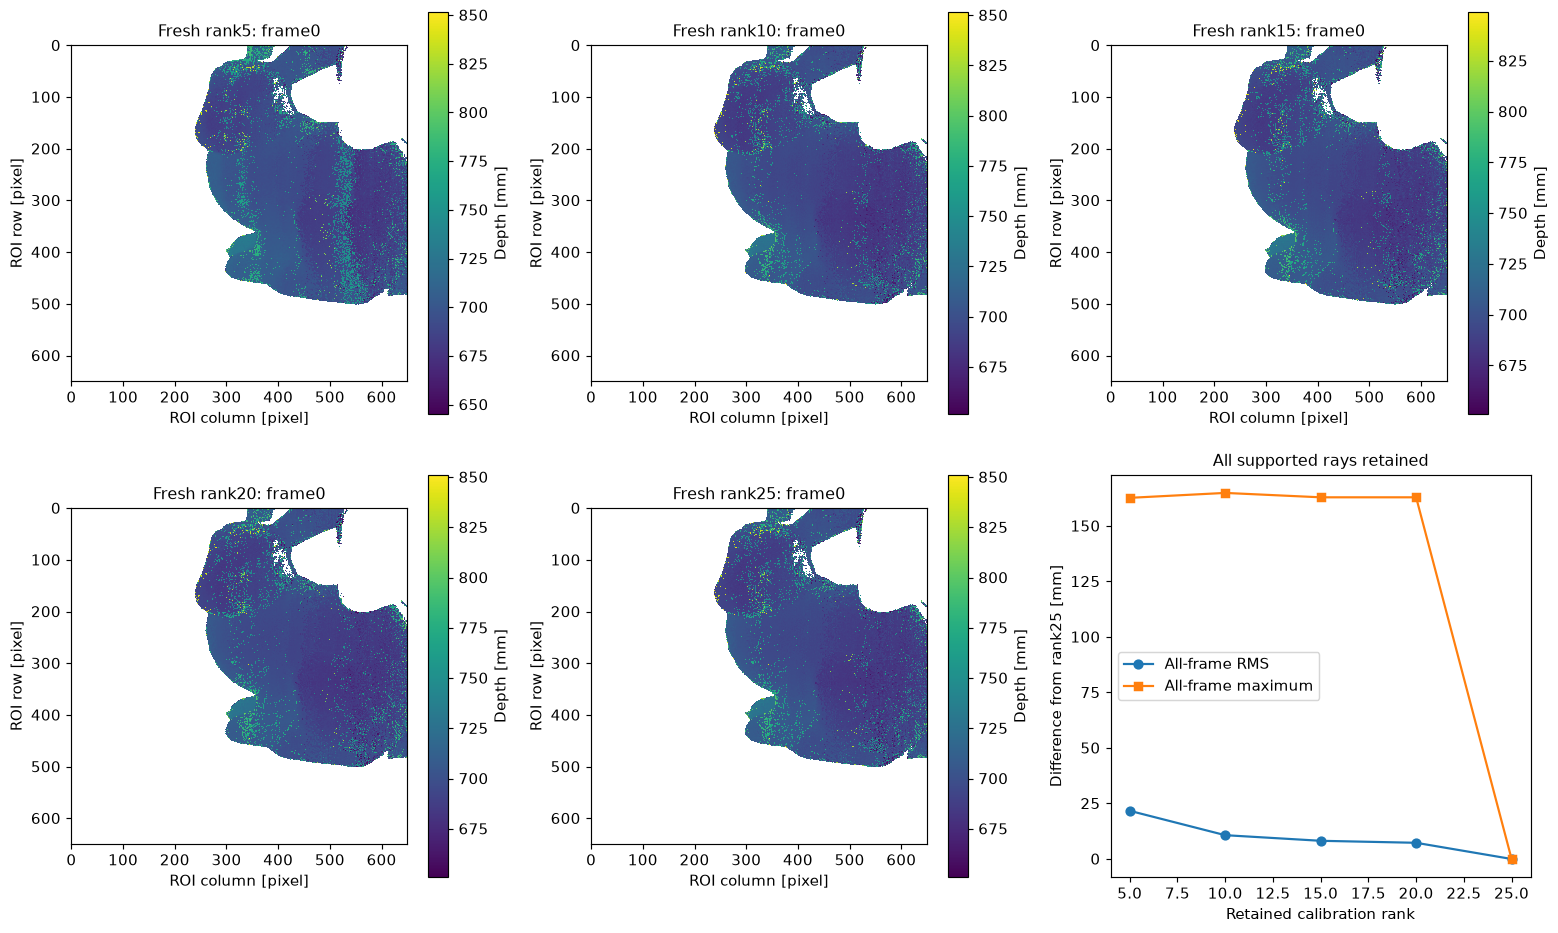

In [7]:
ranks=[5,10,15,20,25]; rank_results=[];rank_stats=[]
for rank in ranks:
    result=fresh if rank==25 else solve(raw,rank=rank)
    rank_results.append(result['reconstruction'])
    delta=(result['reconstruction']-fresh['reconstruction'])[mask].astype(float)
    rank_stats.append([float(np.sqrt(np.mean(delta**2))),float(np.max(abs(delta))),result['seconds']])
rank_results=np.stack(rank_results);rank_stats=np.asarray(rank_stats)
fig,ax=plt.subplots(2,3,figsize=(15,9))
for j,rank in enumerate(ranks):
    im=depth_image(ax.flat[j],rank_results[j,0],mask[0],f'Fresh rank{rank}: frame0');fig.colorbar(im,ax=ax.flat[j],label='Depth [mm]')
ax.flat[5].plot(ranks,rank_stats[:,0],'-o',label='All-frame RMS');ax.flat[5].plot(ranks,rank_stats[:,1],'-s',label='All-frame maximum');ax.flat[5].set(xlabel='Retained calibration rank',ylabel='Difference from rank25 [mm]',title='All supported rays retained');ax.flat[5].legend()
measurements['rank_sensitivity']={'ranks':ranks,'rms_max_seconds':rank_stats.tolist()}
save(fig,'fig05_calibration_compression',dict(ranks=np.array(ranks),depth=rank_results,stats=rank_stats,support=mask),'Allthree fields actively reconstructed at ranks5/10/15/20/25; quantitative comparisons use complete support.')


### Generated ratio perturbations
New additive Gaussian perturbations with standard deviations0.002,0.005,0.01 are generated **in ratio space**, seed232323. They are illustrative algorithm sensitivities, not independently calibrated camera-noise models or uncertainty intervals. Negative noisy ratios are retained. Original input-only support remains fixed.

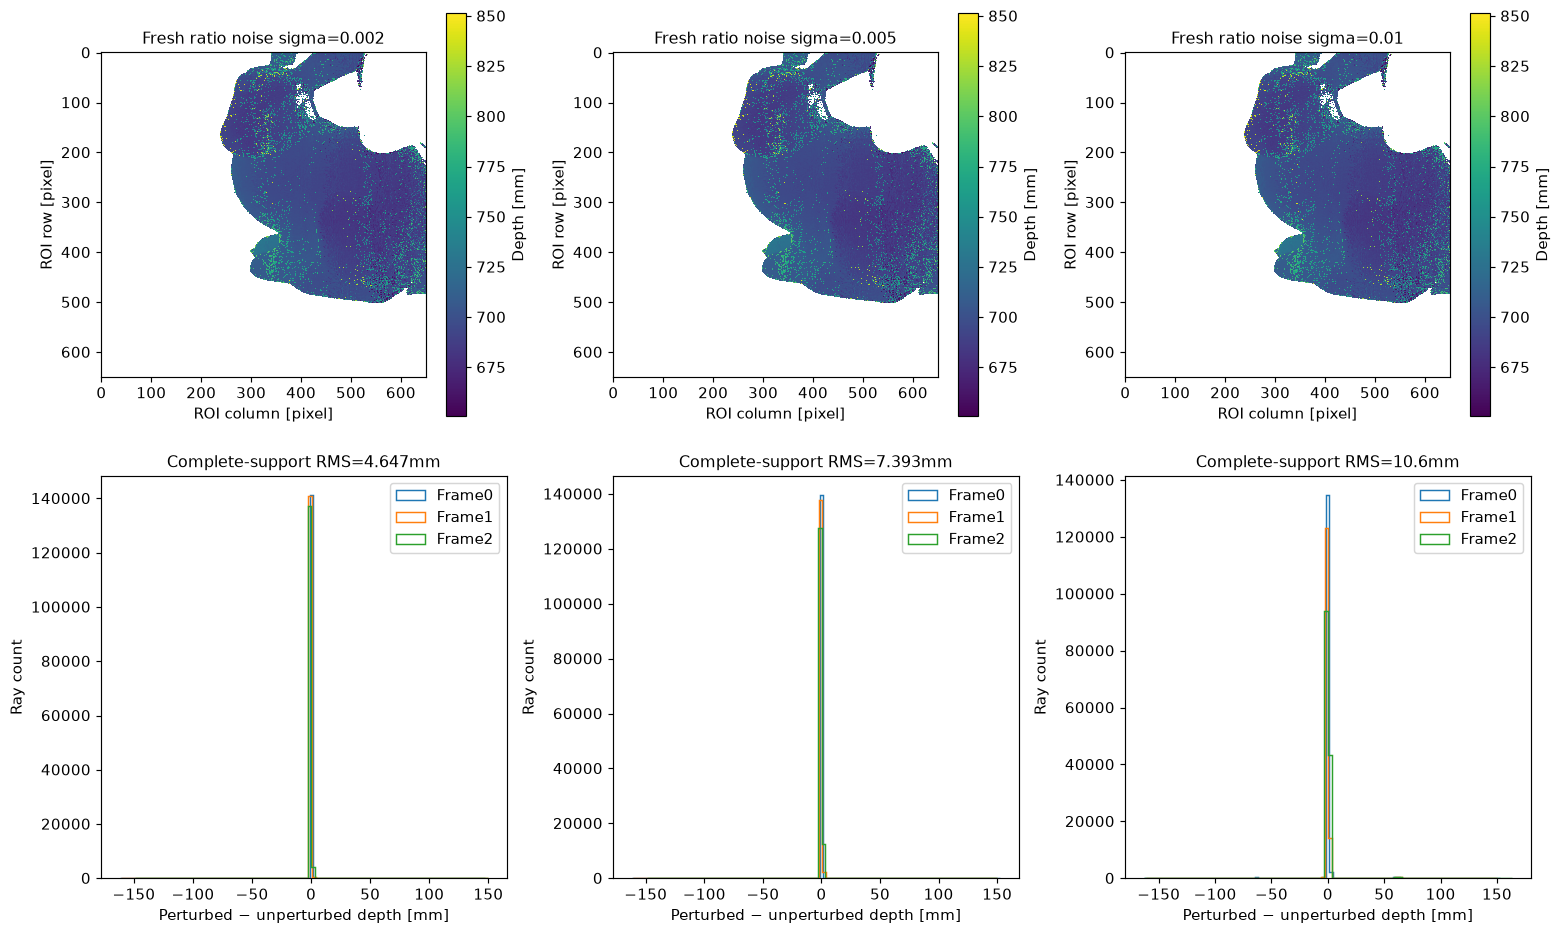

In [8]:
sigmas=[.002,.005,.01];noise_fields=[];noise_stats=[]
for sigma in sigmas:
    noisy=perturb_normalized(q,mask,sigma,seed=232323)
    result=solve(raw,query_override=noisy);noise_fields.append(result['reconstruction'])
    delta=(result['reconstruction']-fresh['reconstruction'])[mask].astype(float)
    noise_stats.append([float(np.sqrt(np.mean(delta**2))),float(np.max(abs(delta)))])
noise_fields=np.stack(noise_fields);noise_stats=np.asarray(noise_stats)
fig,ax=plt.subplots(2,3,figsize=(15,9))
for j,sigma in enumerate(sigmas):
    im=depth_image(ax[0,j],noise_fields[j,0],mask[0],f'Fresh ratio noise sigma={sigma}');fig.colorbar(im,ax=ax[0,j],label='Depth [mm]')
    for f in range(3):
        d=(noise_fields[j,f]-fresh['reconstruction'][f])[mask[f]];ax[1,j].hist(d,bins=100,histtype='step',label=f'Frame{f}')
    ax[1,j].set(title=f'Complete-support RMS={noise_stats[j,0]:.4g}mm',xlabel='Perturbed − unperturbed depth [mm]',ylabel='Ray count');ax[1,j].legend()
measurements['noise_sensitivity']={'sigmas':sigmas,'rms_max_mm':noise_stats.tolist(),'seed':232323}
save(fig,'fig06_generated_ratio_noise',dict(sigmas=np.array(sigmas),depth=noise_fields,stats=noise_stats,support=mask),'Allthree fields actively reconstructed for each ratio-noise level; perturbations are not measured acquisition noise.')


### Four additional real contexts and an uncorrected calibration failure
Before cleaning, four further chronological contexts212,425,637,849 were selected at sequence quartiles and the last complete exposure pair. Frame850 is an empty directory, not a missing measurement filled with synthetic data. They are supplementary real conditions, not replacement benchmarks chosen by output quality.

Two of their supported rays decode to almost zero axial depth, unlike their neighbors. An independent calibration diagnostic finds an isolated near-zero entry at sample510 on those rays, while their other748 samples follow an approximately affine trajectory with maximum residual below0.0002mm. The planar constant-translation hypothesis predicts depth near747mm at that entry. This identifies a supplied calibration inconsistency; it does **not** establish whether its origin is calibration acquisition, invalid board support or compression. No cause, corrected geometry or new mask is invented. The original and fresh bad outputs are retained, with full-range views plus explicitly labelled display zooms.

There is also a separate numerical limitation: four supplementary pixels in frames425/849 choose different nearly tied colors after bounded float32 matrix products. An independently repeated **full-original-shape** operator diagnostic reproduces the archived source choices; comparing exact local blocks shows maximum color differences2.38e−7 to4.17e−7 and squared-objective gaps0 to8.85e−9. The resulting depth differences reach0.684mm. These are explicitly reported below, not asserted to pass the bound three-frame0.001mm parity criterion. No threshold, mask or observation is changed to hide them; all bound three frames remain within their frozen criteria.

[
  {
    "frame": 212,
    "support": 137718,
    "fresh_min_max_mm": [
      649.9842529296875,
      849.9202880859375
    ],
    "depth_below100mm": 0,
    "source_max_difference_mm": 0.00018310546875
  },
  {
    "frame": 425,
    "support": 142418,
    "fresh_min_max_mm": [
      653.1822509765625,
      863.3930053710938
    ],
    "depth_below100mm": 0,
    "source_max_difference_mm": 0.22802734375
  },
  {
    "frame": 637,
    "support": 136987,
    "fresh_min_max_mm": [
      1.0839152309927158e-05,
      871.8849487304688
    ],
    "depth_below100mm": 1,
    "source_max_difference_mm": 0.0001220703125
  },
  {
    "frame": 849,
    "support": 139651,
    "fresh_min_max_mm": [
      2.5563569579389878e-05,
      862.3876342773438
    ],
    "depth_below100mm": 1,
    "source_max_difference_mm": 0.68389892578125
  }
]


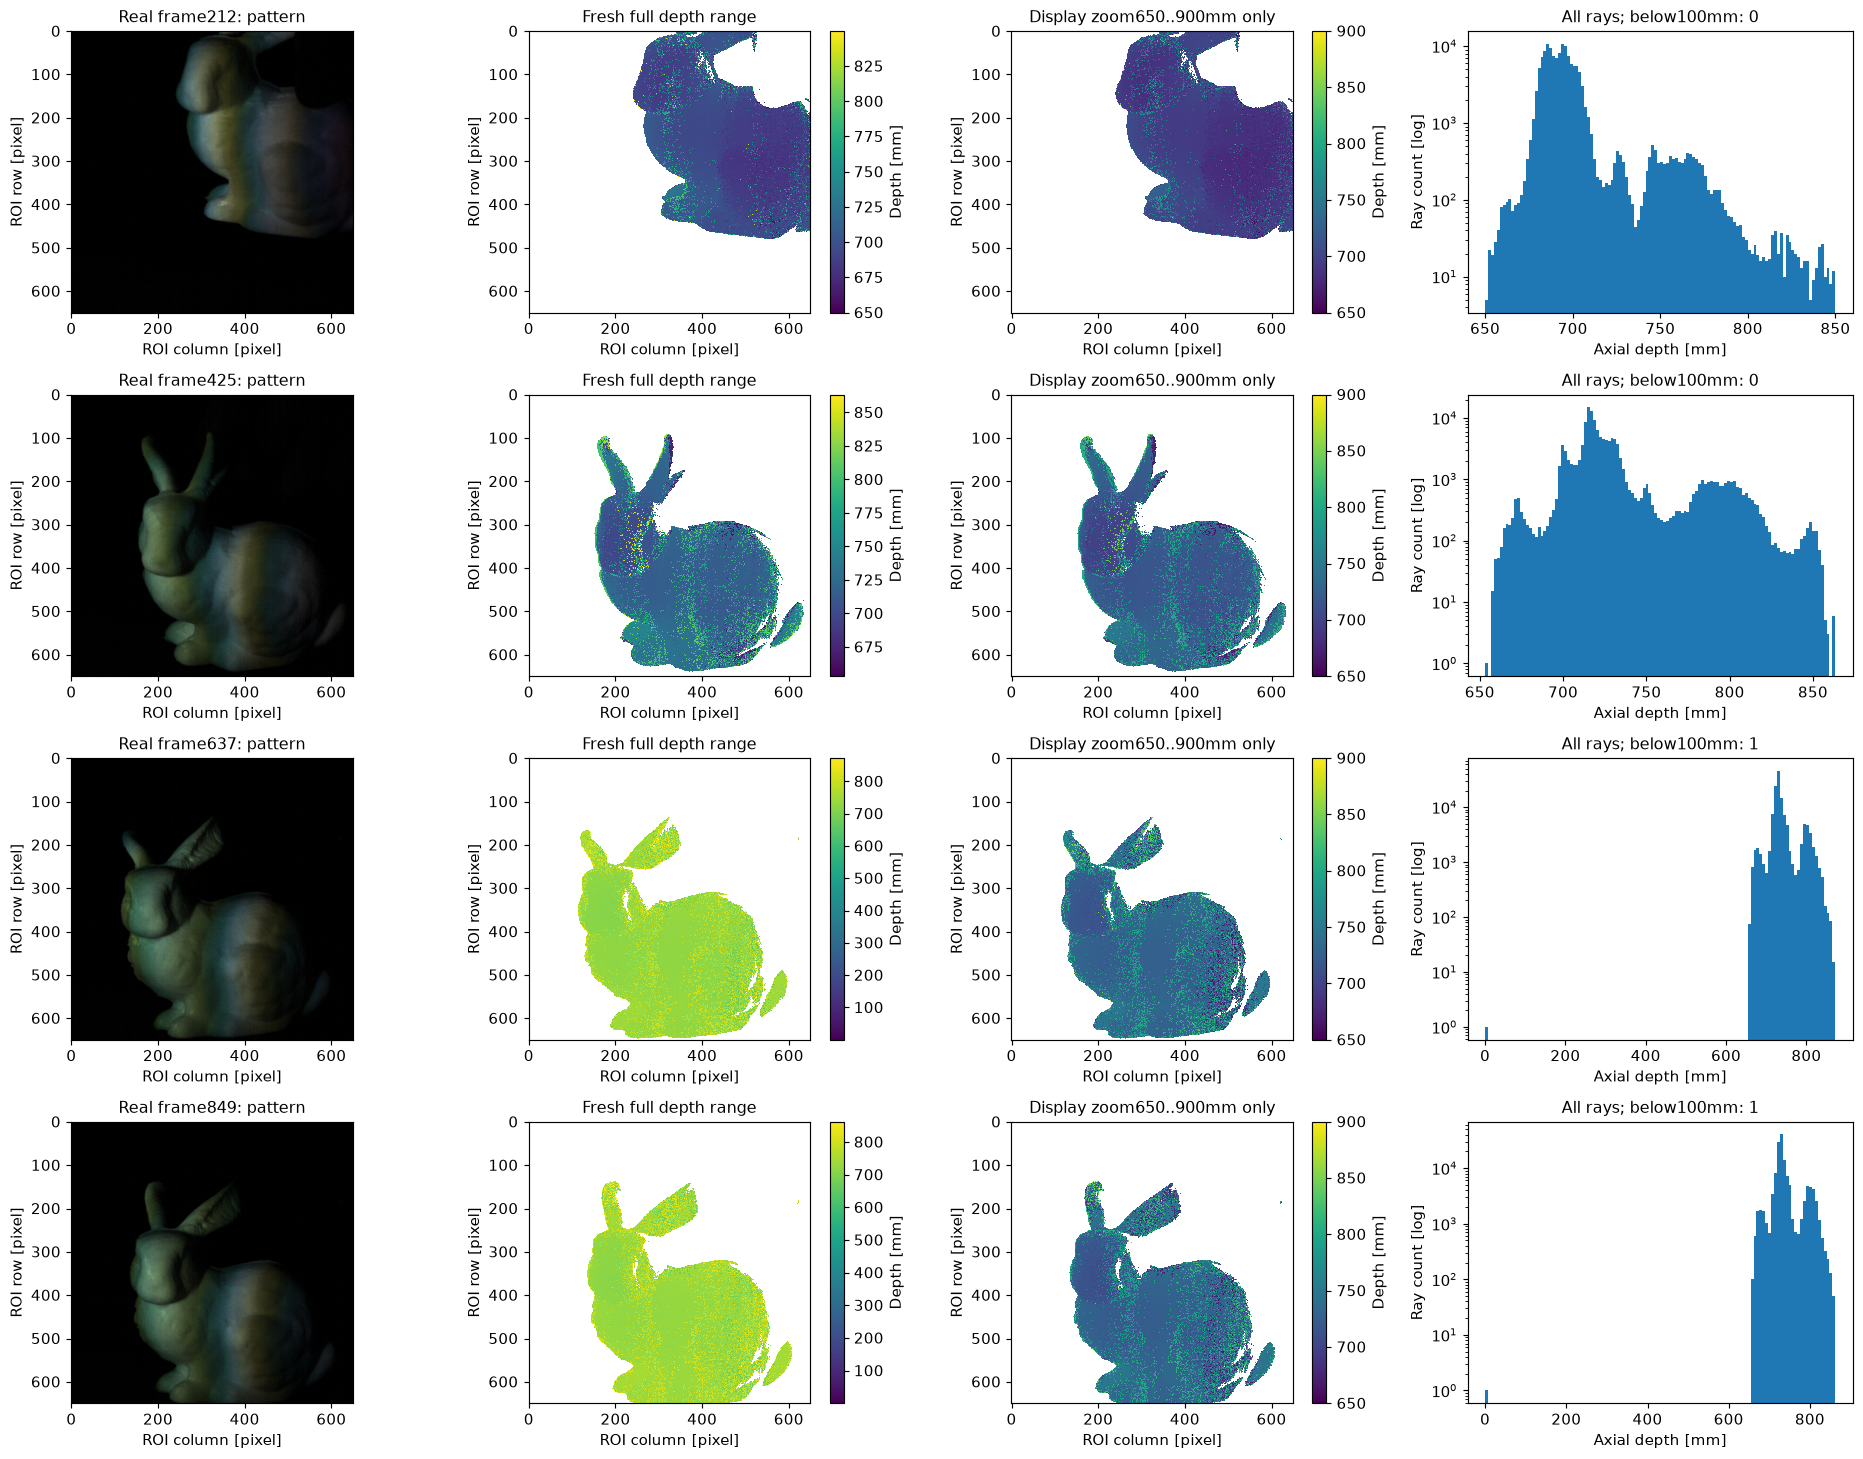

In [9]:
with np.load(ROOT/'test/fixtures/additional_real_conditions.npz',allow_pickle=False) as z: extra_input={k:z[k] for k in z.files}
extra_ids=[212,425,637,849];extra_fields=[];extra_masks=[];extra_stats=[]
fig,ax=plt.subplots(4,4,figsize=(18,14))
for j,frame in enumerate(extra_ids):
    additional=dict(raw);additional['pattern']=extra_input[f'pattern_{frame}'][None,None];additional['white']=extra_input[f'white_{frame}'][None,None]
    result=solve(additional);d=result['reconstruction'][0];m=result['mask'][0];extra_fields.append(d);extra_masks.append(m)
    ref=extra_input[f'depth_{frame}'];row={'frame':frame,'support':int(m.sum()),'fresh_min_max_mm':[float(d[m].min()),float(d[m].max())],'depth_below100mm':int(np.sum(m&(d<100))),'source_max_difference_mm':float(np.max(abs(d-ref)))};extra_stats.append(row)
    ax[j,0].imshow(additional['pattern'][0,0]/4095);ax[j,0].set(title=f'Real frame{frame}: pattern',xlabel='ROI column [pixel]',ylabel='ROI row [pixel]')
    im=depth_image(ax[j,1],d,m,'Fresh full depth range');fig.colorbar(im,ax=ax[j,1],label='Depth [mm]')
    im=depth_image(ax[j,2],d,m,'Display zoom650..900mm only',650,900);fig.colorbar(im,ax=ax[j,2],label='Depth [mm]')
    ax[j,3].hist(d[m],bins=120);ax[j,3].set_yscale('log');ax[j,3].set(title=f'All rays; below100mm: {row["depth_below100mm"]}',xlabel='Axial depth [mm]',ylabel='Ray count [log]')
extra_fields=np.stack(extra_fields);extra_masks=np.stack(extra_masks)
measurements['additional_real_conditions']=extra_stats;print(json.dumps(extra_stats,indent=2))
save(fig,'fig07_additional_real_conditions',dict(frame_ids=np.array(extra_ids),fresh=extra_fields,source=np.stack([extra_input[f'depth_{f}'] for f in extra_ids]),support=extra_masks),'Allfour supplementary real conditions reconstructed freshly. Nearzero depth failures are retained and quantified; zoom panels do not change arrays.')


### Conditioning and calibration trajectory diagnosis
Fixed sensor rays(600,224),(600,220),(600,225),(599,224) permit a direct independent linear least-squares trajectory check excluding sample510. The neighboring row provides a control. This is a diagnostic, not a calibration repair. Full-field measured brightness and RGB-residual distributions additionally expose shadow/model-mismatch limits.

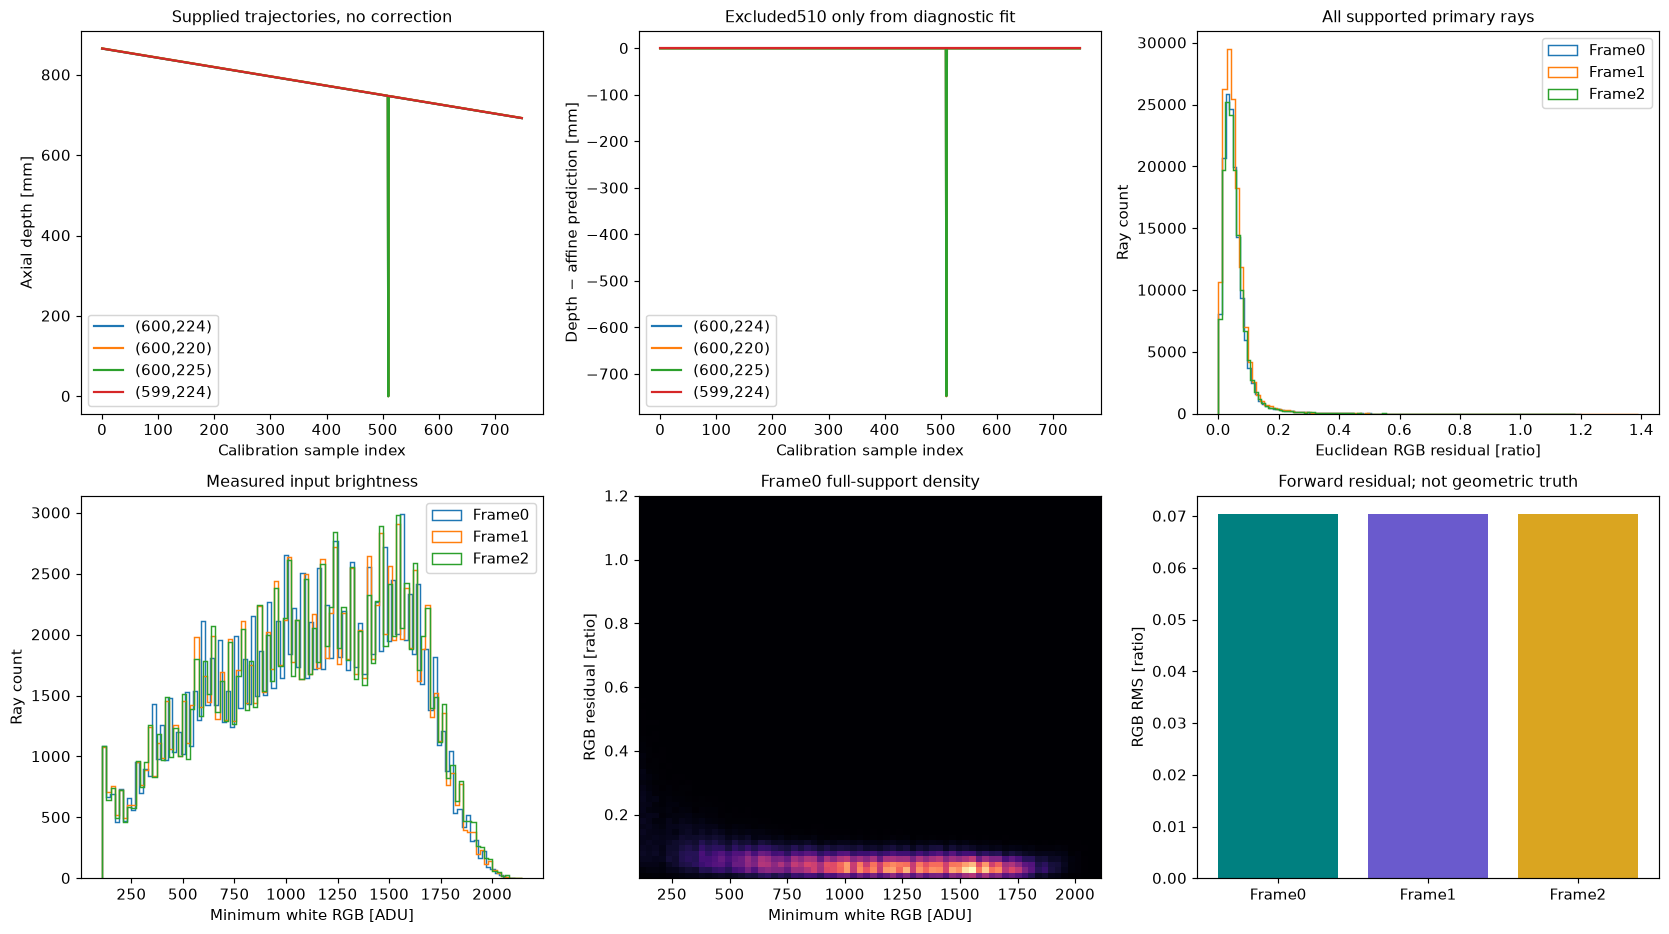

In [10]:
diagnostic_rows=np.array([600*650+224,600*650+220,600*650+225,599*650+224])
_,trajectory=calibration_rays(raw,diagnostic_rows);k=np.arange(749);keep=k!=510
A=np.stack([np.ones(keep.sum()),k[keep]],axis=1);coeff=np.linalg.lstsq(A,trajectory[:,keep].T.astype(float),rcond=None)[0]
prediction=(np.stack([np.ones(749),k],axis=1)@coeff).T
fig,ax=plt.subplots(2,3,figsize=(16,9))
for j,row in enumerate(diagnostic_rows):
    y,x=divmod(int(row),650);ax[0,0].plot(k,trajectory[j],label=f'({y},{x})');ax[0,1].plot(k,trajectory[j]-prediction[j],label=f'({y},{x})')
ax[0,0].set(xlabel='Calibration sample index',ylabel='Axial depth [mm]',title='Supplied trajectories, no correction');ax[0,0].legend()
ax[0,1].set(xlabel='Calibration sample index',ylabel='Depth − affine prediction [mm]',title='Excluded510 only from diagnostic fit');ax[0,1].legend()
for f in range(3):
    loss=fresh['loss'][f][mask[f]];white=raw['white'][0,f].min(axis=-1)[mask[f]]
    ax[0,2].hist(loss,bins=100,histtype='step',label=f'Frame{f}')
    ax[1,0].hist(white,bins=100,histtype='step',label=f'Frame{f}')
    ax[1,1].hist2d(white,loss,bins=70,cmap='magma') if f==0 else None
ax[0,2].set(xlabel='Euclidean RGB residual [ratio]',ylabel='Ray count',title='All supported primary rays');ax[0,2].legend()
ax[1,0].set(xlabel='Minimum white RGB [ADU]',ylabel='Ray count',title='Measured input brightness');ax[1,0].legend()
ax[1,1].set(xlabel='Minimum white RGB [ADU]',ylabel='RGB residual [ratio]',title='Frame0 full-support density')
names=['Frame0','Frame1','Frame2'];rms=[float(np.sqrt(np.mean(fresh['loss'][f][mask[f]].astype(float)**2))) for f in range(3)]
ax[1,2].bar(names,rms,color=['teal','slateblue','goldenrod']);ax[1,2].set(ylabel='RGB RMS [ratio]',title='Forward residual; not geometric truth')
measurements['calibration_diagnostic']={'rows':diagnostic_rows.tolist(),'actual_k510_mm':trajectory[:,510].tolist(),'affine_k510_mm':prediction[:,510].tolist(),'non510_max_abs_mm':np.max(abs(trajectory[:,keep]-prediction[:,keep]),axis=1).tolist()}
save(fig,'fig08_conditioning_and_calibration_failure',dict(rows=diagnostic_rows,trajectory=trajectory,affine=prediction,loss=fresh['loss'],white_min=raw['white'][0].min(axis=-1),support=mask),'Independent trajectory diagnostic plus complete-support brightness/residual distributions. No calibration value or support is corrected.')


## 6. Conclusion
The fresh explicit inverse reconstructs all three bound measured fields, and its independently evaluated numeric agreement with the qualified original is reported above. This establishes method extraction and interface reproducibility, not physical surface accuracy.

The computed spatial/temporal helpers, rank truncations and generated ratio perturbations reveal ambiguity and sensitivity rather than fabricated improvements. Four further real contexts expose near-zero depths caused by supplied calibration entries; all such outputs remain visible. White-normalization assumptions and non-simultaneous exposure motion remain genuine limitations. No geometric ground truth, submillimetre physical accuracy, or paper speedup is inferred from reference agreement.

Provenance, exact revisions, original failures/qualifications, calibration diagnostic, tests, mathematical conventions and all metric definitions are recorded in `test/validation.md` and both maintainer plans. Original files remain private; the solver can reconstruct from README, public observations and environment alone.

In [11]:
measurements['notebook_seconds']=time.perf_counter()-notebook_start
(EXPORT/'measurements.json').write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding='utf8')
(EXPORT/'figure_inventory.json').write_text(json.dumps(figures,indent=2),encoding='utf8')
print({'status':'all_active_experiments_finished','figure_groups':len(figures),'seconds':measurements['notebook_seconds'],'primary_judge':judge['status']})
assert len(figures)==8 and judge['passed']


{'status': 'all_active_experiments_finished', 'figure_groups': 8, 'seconds': 165.87920189999568, 'primary_judge': 'pass'}
